In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_theme(style="whitegrid")


In [2]:
# Load the Titanic CSV file.
# Keep the CSV in the same folder as this notebook.
import os

dataset_options = [
    "titanic_train.csv",
    "titanic_train(2).csv",
    "titanic_train(1).csv"
]

dataset_file = next((file for file in dataset_options if os.path.exists(file)), None)

if dataset_file is None:
    raise FileNotFoundError(
        "Titanic dataset not found. Put titanic_train.csv "
        "(or titanic_train(2).csv) in the notebook folder."
    )

train = pd.read_csv(dataset_file)
print("Loaded dataset:", dataset_file)


Loaded dataset: titanic_train.csv


In [3]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
train.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

<Axes: >

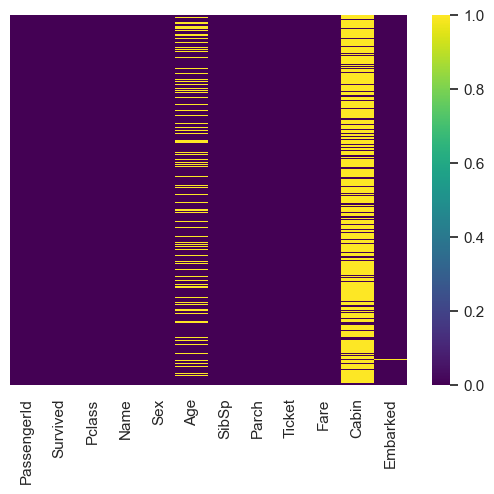

In [5]:
sns.heatmap(train.isnull(),yticklabels=False,cbar=True,cmap='viridis')

Roughly 20 percent of the Age data is missing. The proportion of Age missing is likely small enough for reasonable replacement with some form of imputation. Looking at the Cabin column, it looks like we are just missing too much of that data to do something useful with at a basic level. We'll probably drop this later, or change it to another feature like "Cabin Known: 1 or 0"

Let's continue on by visualizing some more of the data! Check out the video for full explanations over these plots, this code is just to serve as reference.

<Axes: xlabel='Survived', ylabel='count'>

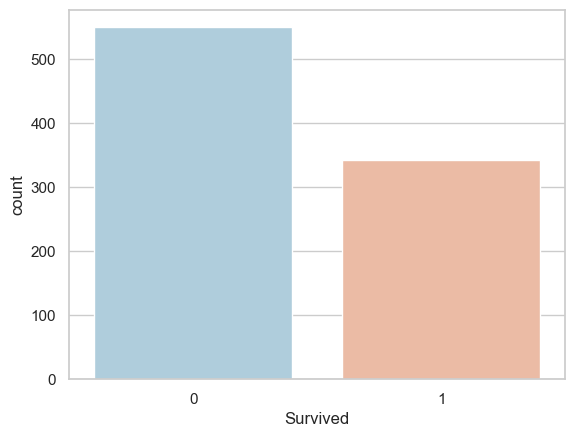

In [6]:
sns.set_style('whitegrid')
sns.countplot(
    x='Survived',
    hue='Survived',
    data=train,
    palette='RdBu_r',
    legend=False
)


<Axes: xlabel='Survived', ylabel='count'>

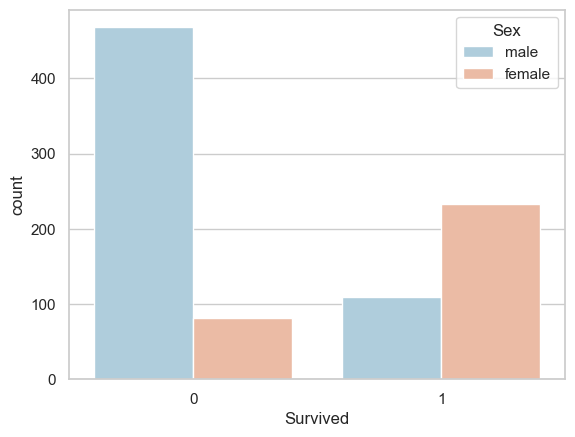

In [7]:
sns.set_style('whitegrid')
sns.countplot(x='Survived', hue='Sex', data=train, palette='RdBu_r')


<Axes: xlabel='Age', ylabel='Density'>

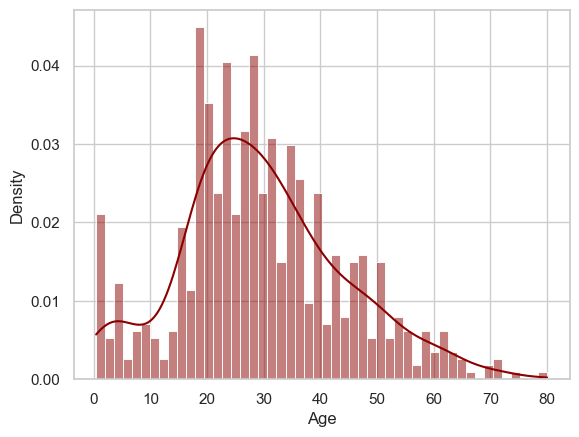

In [8]:
# distplot is deprecated; histplot with KDE gives the same histogram + density curve.
sns.histplot(
    train['Age'].dropna(),
    kde=True,
    color='darkred',
    bins=50,
    stat='density'
)


<Axes: xlabel='SibSp', ylabel='count'>

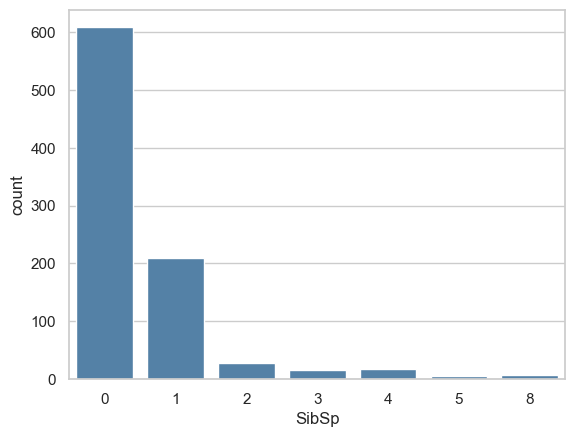

In [9]:
sns.countplot(x='SibSp', data=train, color='steelblue')


<Axes: xlabel='SibSp', ylabel='count'>

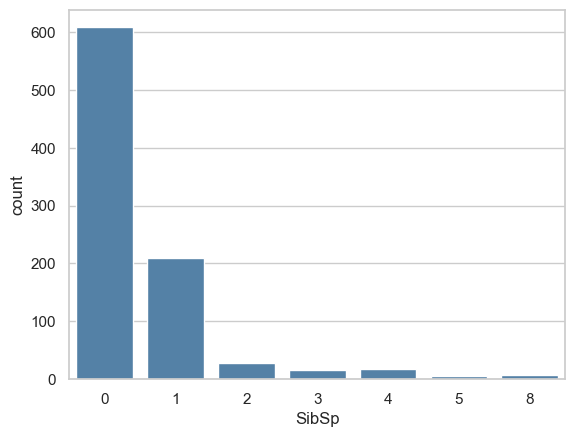

In [10]:
sns.countplot(x='SibSp', data=train, color='steelblue')


<Axes: >

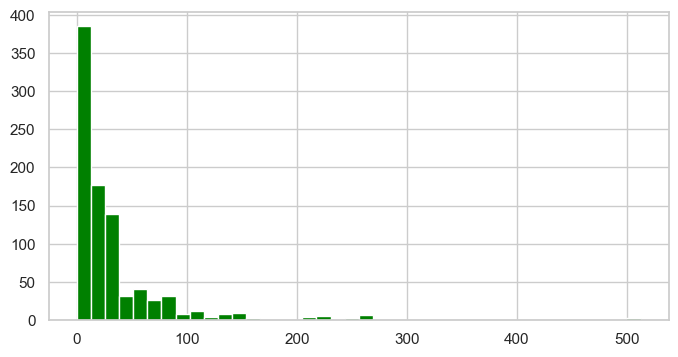

In [11]:
train['Fare'].hist(color='green',bins=40,figsize=(8,4))

<Axes: xlabel='Pclass', ylabel='Age'>

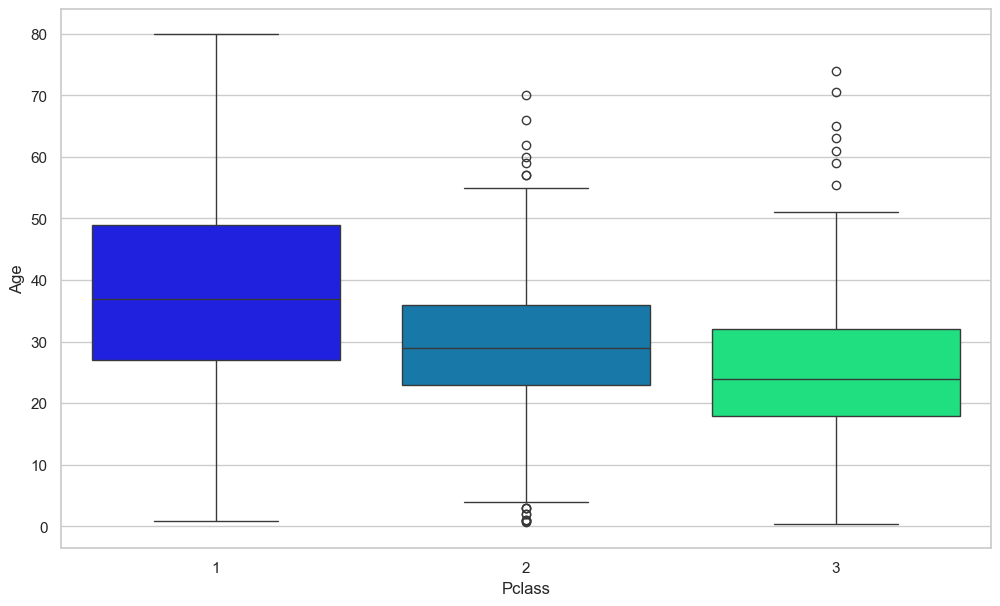

In [12]:
plt.figure(figsize=(12, 7))
sns.boxplot(
    x='Pclass',
    y='Age',
    data=train,
    hue='Pclass',
    palette='winter',
    legend=False
)


We can see the wealthier passengers in the higher classes tend to be older, which makes sense. We'll use these average age values to impute based on Pclass for Age.

In [13]:
def impute_age(cols):
    Age = cols.iloc[0]
    Pclass = cols.iloc[1]

    if pd.isnull(Age):
        if Pclass == 1:
            return 37
        elif Pclass == 2:
            return 29
        else:
            return 24
    else:
        return Age


Now apply that function!

In [14]:
train['Age'] = train[['Age','Pclass']].apply(impute_age,axis=1)

Now let's check that heat map again!

<Axes: >

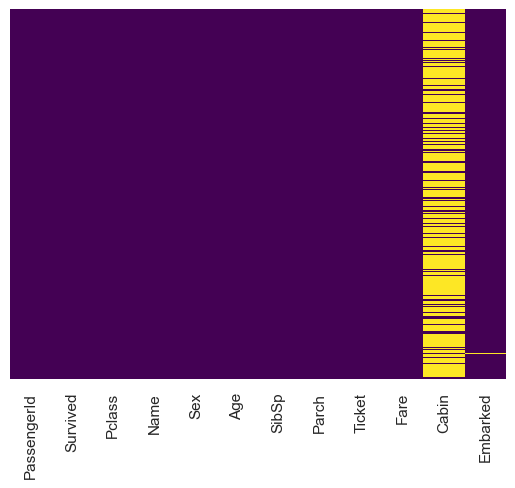

In [15]:
sns.heatmap(train.isnull(),yticklabels=False,cbar=False,cmap='viridis')

<Axes: xlabel='Age'>

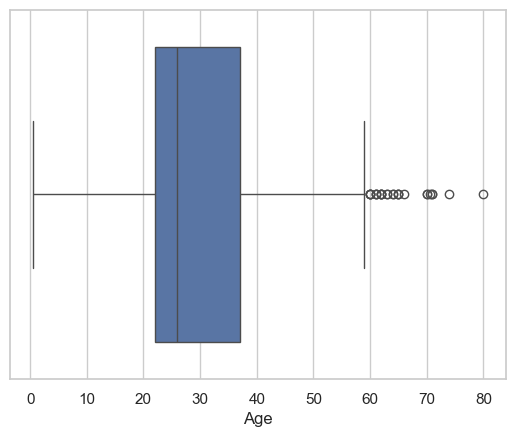

In [16]:
sns.boxplot(x=train['Age'])

<Axes: xlabel='Fare'>

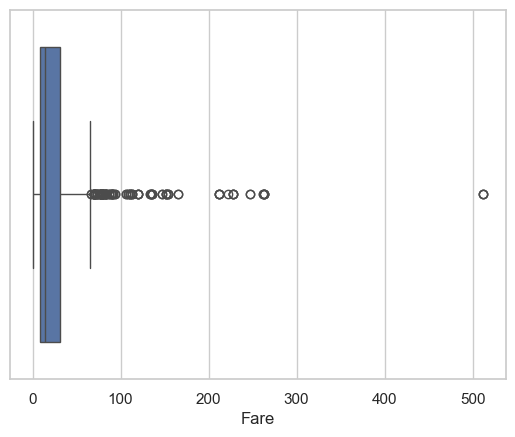

In [17]:
sns.boxplot(x=train['Fare'])

In [18]:
q1 = train['Fare'].quantile(0.25)
q2 = train['Fare'].quantile(0.50)
q3 = train['Fare'].quantile(0.75)
median =  train['Fare'].median()
print("Q1 :",q1)
print("Q2 :",q2)
print("Q3 :",q3)
print("median :",median)

iqr = q3 - q1

upper_tail = q3 + 3*iqr
lower_tail = q1 - 3*iqr
print("Upper Tail :",upper_tail)
print("Lower Tail :",lower_tail)

Q1 : 7.9104
Q2 : 14.4542
Q3 : 31.0
median : 14.4542
Upper Tail : 100.2688
Lower Tail : -61.358399999999996


In [19]:
train[['Fare']].loc[train['Fare'] > upper_tail].shape

(53, 1)

In [20]:
median_fare = train.loc[(train['Fare'] <= upper_tail) &
                            (train['Fare'] >= lower_tail),'Fare'].median()

median_fare

13.0

In [21]:
train.loc[(train['Fare'] > upper_tail) | (train['Fare'] < lower_tail),'Fare'] = median_fare

In [22]:
train.loc[(train['Fare'] > upper_tail) |
                            (train['Fare'] < lower_tail),'Fare']

Series([], Name: Fare, dtype: float64)

In [23]:
train['Fare']

0       7.2500
1      71.2833
2       7.9250
3      53.1000
4       8.0500
        ...   
886    13.0000
887    30.0000
888    23.4500
889    30.0000
890     7.7500
Name: Fare, Length: 891, dtype: float64

In [24]:
q1 = train['Age'].quantile(0.25)
q2 = train['Age'].quantile(0.50)
q3 = train['Age'].quantile(0.75)
median =  train['Age'].median()
print("Q1 :",q1)
print("Q2 :",q2)
print("Q3 :",q3)
print("median :",median)

iqr = q3 - q1

upper_tail = q3 + 3*iqr
lower_tail = q1 - 3*iqr
print("Upper Tail :",upper_tail)
print("Lower Tail :",lower_tail)

Q1 : 22.0
Q2 : 26.0
Q3 : 37.0
median : 26.0
Upper Tail : 82.0
Lower Tail : -23.0


In [25]:
median_Age = train.loc[(train['Age'] <= upper_tail) &
                            (train['Age'] >= lower_tail),'Age'].median()

median_Age

26.0

In [26]:
train.loc[(train['Age'] > upper_tail) | (train['Age'] < lower_tail),'Age'] = median_Age

In [27]:
train.loc[
    (train['Age'] > upper_tail) |
    (train['Age'] < lower_tail),
    'Age'
]


Series([], Name: Age, dtype: float64)

In [28]:
train['Age']

0      22.0
1      38.0
2      26.0
3      35.0
4      35.0
       ... 
886    27.0
887    19.0
888    24.0
889    26.0
890    32.0
Name: Age, Length: 891, dtype: float64

In [29]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
train[['Age', 'Fare']] = scaler.fit_transform(train[['Age', 'Fare']])


In [30]:
train['Age']

0     -0.533834
1      0.674891
2     -0.231653
3      0.448255
4      0.448255
         ...   
886   -0.156107
887   -0.760469
888   -0.382743
889   -0.231653
890    0.221619
Name: Age, Length: 891, dtype: float64

In [31]:
train['Fare']

0     -0.719010
1      2.434003
2     -0.685772
3      1.538654
4     -0.679617
         ...   
886   -0.435878
887    0.401205
888    0.078682
889    0.401205
890   -0.694389
Name: Fare, Length: 891, dtype: float64

Great! Let's go ahead and drop the Cabin column and the row in Embarked that is NaN.

In [32]:
train.drop('Cabin',axis=1,inplace=True)

In [33]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,-0.533834,1,0,A/5 21171,-0.719010,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,0.674891,1,0,PC 17599,2.434003,C
2,3,1,3,"Heikkinen, Miss. Laina",female,-0.231653,0,0,STON/O2. 3101282,-0.685772,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,0.448255,1,0,113803,1.538654,S
4,5,0,3,"Allen, Mr. William Henry",male,0.448255,0,0,373450,-0.679617,S


In [34]:
train.isna().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       2
dtype: int64

In [35]:
train.dropna(inplace=True)

In [36]:
train.isna().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

In [37]:
train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 889 entries, 0 to 890
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  889 non-null    int64  
 1   Survived     889 non-null    int64  
 2   Pclass       889 non-null    int64  
 3   Name         889 non-null    object 
 4   Sex          889 non-null    object 
 5   Age          889 non-null    float64
 6   SibSp        889 non-null    int64  
 7   Parch        889 non-null    int64  
 8   Ticket       889 non-null    object 
 9   Fare         889 non-null    float64
 10  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(4)
memory usage: 83.3+ KB


In [38]:
train=pd.get_dummies(train,columns=['Sex','Embarked'])

In [39]:
train.head()

,PassengerId,Survived,Pclass,Name,Age,SibSp,Parch,Ticket,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,1,0,3,"Braund, Mr. Owen Harris",-0.533834,1,0,A/5 21171,-0.719010,False,True,False,False,True
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0.674891,1,0,PC 17599,2.434003,True,False,True,False,False
2,3,1,3,"Heikkinen, Miss. Laina",-0.231653,0,0,STON/O2. 3101282,-0.685772,True,False,False,False,True
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0.448255,1,0,113803,1.538654,True,False,False,False,True
4,5,0,3,"Allen, Mr. William Henry",0.448255,0,0,373450,-0.679617,False,True,False,False,True


In [40]:
train.drop(['Name','Ticket'],axis=1,inplace=True)

In [41]:
train.head()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,1,0,3,-0.533834,1,0,-0.719010,False,True,False,False,True
1,2,1,1,0.674891,1,0,2.434003,True,False,True,False,False
2,3,1,3,-0.231653,0,0,-0.685772,True,False,False,False,True
3,4,1,1,0.448255,1,0,1.538654,True,False,False,False,True
4,5,0,3,0.448255,0,0,-0.679617,False,True,False,False,True


In [42]:
from sklearn.model_selection import train_test_split

In [43]:
X = train.drop('Survived',axis=1)
y = train['Survived']

In [44]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.30,random_state=101)

In [45]:
from sklearn.linear_model import LogisticRegression

In [46]:
from sklearn.linear_model import LogisticRegression

logmodel = LogisticRegression(max_iter=1000)

logmodel.fit(X_train, y_train)

predictions = logmodel.predict(X_test)


In [47]:
predictions = logmodel.predict(X_test)

Let's move on to evaluate our model!

We can check precision,recall,f1-score using classification report!

In [48]:
from sklearn.metrics import classification_report, confusion_matrix

In [49]:
print(classification_report(y_test,predictions))

              precision    recall  f1-score   support

           0       0.82      0.90      0.85       163
           1       0.81      0.68      0.74       104

    accuracy                           0.81       267
   macro avg       0.81      0.79      0.80       267
weighted avg       0.81      0.81      0.81       267



In [50]:
print(confusion_matrix(y_test,predictions))

[[146  17]
 [ 33  71]]
